# Ridge paths with matched penalty conventions

Ridge minimizes
$$\frac{1}{2n}\|Xb-y\|^2+\frac{\lambda}{2}\|b_{\mathrm{slopes}}\|^2.$$
The intercept is unpenalized. This notebook compares TRU, ARC and scikit-learn
on the *same* ridge problem, then selects the penalty using a separate validation
sample and evaluates it on a held-out test sample.

`sklearn.linear_model.Ridge` uses a sum-loss convention: its matching parameter is
`alpha = n_train * lambda`. The prototype currently implements L2-penalized
linear regression; no L1 penalty or constrained-ball estimator is implied.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1005)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from sklearn.linear_model import Ridge as SkRidge
from galahad_econometrics import OLS, Ridge

n_train, n_valid, n_test, p = 120, 800, 2000, 40
correlation = .75 ** np.abs(np.arange(p)[:, None] - np.arange(p)[None, :])
L = np.linalg.cholesky(correlation)
beta = np.zeros(p)
beta[:6] = [1.5, -1., .8, -.7, .5, -.3]
intercept = .4

def draw(n):
    X = rng.normal(size=(n, p)) @ L.T
    y = intercept + X @ beta + 1.5*rng.normal(size=n)
    return X, y

X_train, y_train = draw(n_train)
X_valid, y_valid = draw(n_valid)
X_test, y_test = draw(n_test)
penalties = np.r_[0., np.logspace(-4, 1, 12)]

## Fit the entire path

Predictions are generated in the original feature units. `penalty=0` reproduces
OLS, and a scalar penalty excludes the added intercept. No standard errors are
requested for the regularized fit. The tolerance controls the optimization
criterion rather than statistical uncertainty.

In [3]:
rows, coefficients = [], {"TRU": [], "ARC": [], "scikit-learn": []}
for penalty in penalties:
    native = {}
    for name, solver in [("TRU", "tru"), ("ARC", "arc")]:
        fit = Ridge(X_train, y_train, penalty=penalty).fit(solver=solver)
        assert fit.success
        native[name] = fit
        coefficients[name].append(fit.params)
        rows.append({"method": name, "penalty": penalty,
                     "validation MSE": np.mean((fit.predict(X_valid)-y_valid)**2),
                     "test MSE": np.mean((fit.predict(X_test)-y_test)**2),
                     "slope RMSE": np.sqrt(np.mean((fit.params[1:]-beta)**2))})
    ref = SkRidge(alpha=n_train*penalty, fit_intercept=True, solver="cholesky").fit(X_train, y_train)
    ref_params = np.r_[ref.intercept_, ref.coef_]
    coefficients["scikit-learn"].append(ref_params)
    assert np.max(np.abs(native["TRU"].params-ref_params)) < 2e-6
    assert np.max(np.abs(native["ARC"].params-ref_params)) < 2e-6
    rows.append({"method": "scikit-learn", "penalty": penalty,
                 "validation MSE": np.mean((ref.predict(X_valid)-y_valid)**2),
                 "test MSE": np.mean((ref.predict(X_test)-y_test)**2),
                 "slope RMSE": np.sqrt(np.mean((ref.coef_-beta)**2))})

path = pd.DataFrame(rows)
selected = path.loc[path.groupby("method")["validation MSE"].idxmin()].set_index("method")
selected

,penalty,validation MSE,test MSE,slope RMSE
method,,,,
ARC,0.15199,2.8958,2.8262,0.26364
TRU,0.15199,2.8958,2.8262,0.26364
scikit-learn,0.15199,2.8958,2.8262,0.26364


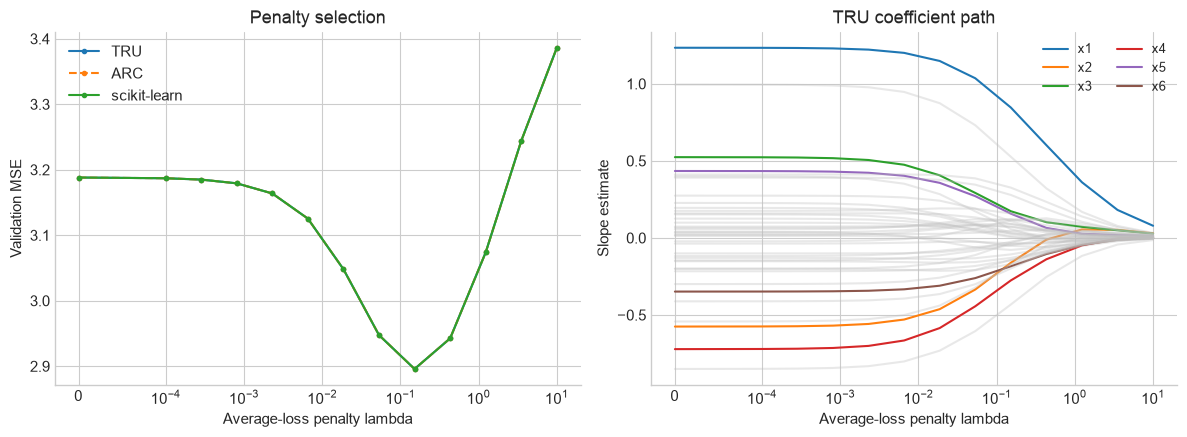

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for method, frame in path.groupby("method", sort=False):
    axes[0].plot(frame["penalty"], frame["validation MSE"], marker=".",
                 linestyle="--" if method == "ARC" else "-", label=method)
axes[0].set_xscale("symlog", linthresh=1e-4)
axes[0].set(xlabel="Average-loss penalty lambda", ylabel="Validation MSE", title="Penalty selection")
axes[0].legend()
coefs = np.array(coefficients["TRU"])
for j in range(p):
    axes[1].plot(penalties, coefs[:, j+1], color=f"C{j}" if j < 6 else "0.75",
                 alpha=1 if j < 6 else .35, label=f"x{j+1}" if j < 6 else None)
axes[1].set_xscale("symlog", linthresh=1e-4)
axes[1].set(xlabel="Average-loss penalty lambda", ylabel="Slope estimate", title="TRU coefficient path")
axes[1].legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

## Evaluate the selected fit once

The selected penalties minimize validation MSE, never test MSE. The reported
slope RMSE averages squared coefficient errors over the 40 slopes of each named
fit. The test MSE averages squared prediction errors over 2,000 independent test
observations. The three numerical implementations should agree because their
penalties and intercept conventions match exactly.

In [5]:
ols = OLS(X_train, y_train).fit()
chosen_penalty = float(selected.loc["TRU", "penalty"])
chosen = Ridge(X_train, y_train, penalty=chosen_penalty).fit()
assert np.max(np.abs(np.array(coefficients["TRU"])-np.array(coefficients["scikit-learn"]))) < 2e-6
pd.DataFrame({"OLS": {"test MSE": np.mean((ols.predict(X_test)-y_test)**2),
                       "slope RMSE": np.sqrt(np.mean((ols.params[1:]-beta)**2))},
              "Validation-selected ridge": {"test MSE": np.mean((chosen.predict(X_test)-y_test)**2),
                                             "slope RMSE": np.sqrt(np.mean((chosen.params[1:]-beta)**2))}}).T

,test MSE,slope RMSE
OLS,3.0811,0.29929
Validation-selected ridge,2.8262,0.26364


Regularization trades approximation bias against sampling variance. Agreement
between solvers establishes numerical equivalence on these samples; it does not
choose a statistically optimal penalty for other datasets or justify
unregularized standard errors for a ridge estimate.